<a href="https://colab.research.google.com/github/ArtemFirst1/DataLoves_homework/blob/main/%22HW_2_1_%D0%9B%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_%D0%B2%D1%96%D0%B4_%D0%B1%D0%B0%D0%B3%D0%B0%D1%82%D1%8C%D0%BE%D1%85_%D0%B7%D0%BC%D1%96%D0%BD%D0%BD%D0%B8%D1%85_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В цьому домашньому завданні ми з вами побудуємо повноцінне ML-рішення реальної ML-задачі. Ви вже маєте всі знання, які для цього потрібні. Дотримуйтесь інструкцій, та користуйтесь матеріалами лекцій, аби виконувати завдання. Тут інструкції будуть детальні, а в подільших завданнях - будуть ставати все менш детальними, аби ви вже починали самостійно структурувати ML-проєкт і до кінця курсу для вас розвʼязати будь-яку ML–задачу було eazy-breezy.

## Dataset

Будемо працювати з набором даних `cars.csv`, який описує автомобілі і їх ціну у індійських рупіях :) Мета - передбачити ціну авто за його характеристиками. Опис набору даних:

| Назва рядка            | Опис                                                                                                                                                 |
|------------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------|
| Car_ID                 | Унікальний ідентифікатор для кожного оголошення про автомобіль.                                                                                         |
| Brand                  | Бренд або виробник автомобіля (наприклад, Toyota, Honda, Ford тощо).                                                                                     |
| Model                  | Модель автомобіля (наприклад, Camry, Civic, Mustang тощо).                                                                                               |
| Year                   | Рік виготовлення автомобіля.                                                                                                                            |
| Kilometers_Driven      | Загальний пробіг автомобіля у кілометрах.                                                                                                               |
| Fuel_Type              | Тип палива, який використовує автомобіль (наприклад, бензин, дизель, електро тощо).                                                                      |
| Transmission           | Тип трансмісії автомобіля (наприклад, механічна, автоматична).                                                                                           |
| Owner_Type             | Кількість попередніх власників автомобіля (наприклад, перший, другий, третій).                                                                           |
| Mileage                | Паливна ефективність автомобіля у кілометрах на літр.                                                                                                   |
| Engine                 | Об'єм двигуна автомобіля в кубічних сантиметрах (CC).                                                                                                   |
| Power                  | Максимальна потужність автомобіля в кінських силах (bhp).                                                                                               |
| Seats                  | Кількість місць в автомобілі.                                                                                                                           |
| Price                  | Вартість автомобіля в INR (індійські рупії), що є цільовою змінною для прогнозування.                                                                   |

# Імпорти

Для зручності рекомендую всі імпорти розмістити тут нагорі, аби коли ви перезавантажували ноутбук, одразу можна було в один запуск клітинки імпортувати всі потрібні бібліотеки.

**Пи.си.** Дякую, так і роблю завжди )

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm

# Знайомство з даними

**Завдання 1.** Завантажте набір даних `cars.csv` в pandas.DataFrame. Виведіть перші 5 записів.

In [12]:
cars = pd.read_csv('/content/cars.csv')
cars.head()

,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,1,Toyota,Corolla,2018,50000,Petrol,Manual,First,15,1498,108,5,800000
1,2,Honda,Civic,2019,40000,Petrol,Automatic,Second,17,1597,140,5,1000000
2,3,Ford,Mustang,2017,20000,Petrol,Automatic,First,10,4951,395,4,2500000
3,4,Maruti,Swift,2020,30000,Diesel,Manual,Third,23,1248,74,5,600000
4,5,Hyundai,Sonata,2016,60000,Diesel,Automatic,Second,18,1999,194,5,850000


**Завдання 2.** Виведіть типи даних колонок даних, а також дослідіть, які по факту типи даних мають записи в кожній колонці (тип `object` може містити різні типи даних) і скільки значень є в кожній категоріальній колонці.

Напишіть висновок, скільки в наборі даних числових та категоріальних колонок кожного з трьох різних типів (бінарна, мільтикатегоріальна без порядку, мультикатегоріальна з порядком). Шаблон висновку

```
В наборі даних 10 числових і 10 категоріальних колонок з них
- 2 бінарні (мають лише 2 значення)
- 6 мультикатегоріальних (більше 2х значень) зі значеннями, для яких немає відношення порядку
- 2 колонки, в яких можна встановити відношення порядку (наприклад Small<Medium<Large)
```

Якщо не знаєте, як це зробити з `pandas` - ось підказка, які методи можуть допомогти вам виконати це завдання

- pandas.DataFrame.info()
- pandas.DataFrame.dtypes
- pandas.DataFrame.loc[...]
- pandas.DataFrame.select_dtypes(...)
- pandas.Series.unique()
- pandas.Series.nunique()

Детальніше ознайомитись з кожним ви можете в [документації](https://pandas.pydata.org/docs/reference/frame.html), або написати в окремій клітинці знак питання і назву методу (тільки приберіть це перед здачею, бо перегляд документації - не допомагає зрозуміти дані і хід думок, а Ваша робота - це як презентація замовнику зробленої задачі).


In [3]:
# приклад як викликати документацію, якщо у Вас pandas імпортований як pd
?pd.DataFrame.info

In [13]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Car_ID             100 non-null    int64 
 1   Brand              100 non-null    object
 2   Model              100 non-null    object
 3   Year               100 non-null    int64 
 4   Kilometers_Driven  100 non-null    int64 
 5   Fuel_Type          100 non-null    object
 6   Transmission       100 non-null    object
 7   Owner_Type         100 non-null    object
 8   Mileage            100 non-null    int64 
 9   Engine             100 non-null    int64 
 10  Power              100 non-null    int64 
 11  Seats              100 non-null    int64 
 12  Price              100 non-null    int64 
dtypes: int64(8), object(5)
memory usage: 10.3+ KB


In [14]:
print('\nТипи даних колонок:')
print(cars.dtypes)

print('\nФактичні типи даних:')
print(cars.apply(lambda col: col.map(type).unique()))

print('\nКількість унікальних категоріальних значень:')
print(cars.select_dtypes('object').nunique())

print('\nКількість числових колонок:')
print(cars.select_dtypes('number').shape[1])

print('\nКількість категоріальних колонок:')
print(cars.select_dtypes('object').shape[1])


Типи даних колонок:
Car_ID                int64
Brand                object
Model                object
Year                  int64
Kilometers_Driven     int64
Fuel_Type            object
Transmission         object
Owner_Type           object
Mileage               int64
Engine                int64
Power                 int64
Seats                 int64
Price                 int64
dtype: object

Фактичні типи даних:
          Car_ID          Brand          Model           Year  \
0  <class 'int'>  <class 'str'>  <class 'str'>  <class 'int'>   

  Kilometers_Driven      Fuel_Type   Transmission     Owner_Type  \
0     <class 'int'>  <class 'str'>  <class 'str'>  <class 'str'>   

         Mileage         Engine          Power          Seats          Price  
0  <class 'int'>  <class 'int'>  <class 'int'>  <class 'int'>  <class 'int'>  

Кількість унікальних категоріальних значень:
Brand           11
Model           58
Fuel_Type        2
Transmission     2
Owner_Type       3
dtype: int64

**Висновок**: У наборі даних 8 числових і 5 категоріальних колонок, з них:
- 2 бінарні — Fuel_Type та Transmission (по 2 значення);
- 2 мультикатегоріальні без порядку — Brand (11 значень) та Model (58 значень);
- 1 мультикатегоріальна з порядком — Owner_Type (3 значення).
У числових колонках зберігаються цілі числа, а в категоріальних — рядки.

**Завдання 3**. Розділіть дані на тренувальні і тест. Відведіть в тест 20%, поставте `random_state=12`. Ми будемо передбачати колонку `Price` - тож, вона є цільовою змінною. В результаті у Вас має бути 4 набори даних `X_train, X_test, y_train, y_test`.

Надалі ми всюди тренуємо методи для кодування, масштабування та саму модель тільки на тренувальних даних X_train (та y_train для моделі), а на тестувальних лише використовуємо вже навчені методи для кодування, масштабування і модель викликаючи в них `transform()` (для методів обробки даних) або `predict()` (для моделі).

І так само треба робити завжди.

In [15]:
X = cars.drop(columns=['Price'])
y = cars['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12)
X_train = X_train.copy()
X_test = X_test.copy()

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(80, 12) (20, 12) (80,) (20,)


**Завдання 4**. Кодуємо категоріальні колонки.

1. Закодуйте колонки з бінарними значеннями `Fuel_Type` і `Transmission` так, аби вони були у чисельному представленні і містили лише 0 так 1. Приклад був у лекції. Значення 1 нехай буде у категорії, яка містить більше значень в колонці.

2. Закодуйте колонку `Brand` з використанням `sklearn.preprocessing.OneHotEncoder` аналогічно до того, як ми робили це в лекції. Увага! Ми робимо виклик методу `Encoder.fit()` на тренувальних даних `X_train`, а на тестувальних тільки викликаємо `Encoder.transform()`. Додайте закодовані значення в набори даних `X_train`, `X_test`.

3. Колонку `Owner_Type` з використанням `sklearn.preprocessing.OrdinalEncoder` я закодую для вас. Проаналізуйте, що відбувається.

Колонка `Model` містять забагато значень для кодування в тому вигляді, як вона є зараз, з огляду на невелику кількість даних. Якщо ви бачите, як можна згрупувати значення в цій колонці скоротивши кількість унікальних значень до 3-5, то можете виконати ще цю трансформацію, використати цю колонку в моделі і отримати додаткову практику і бал, якщо все буде зроблено правильно. А якщо неправильно - то фідбек на Вашу роботу :)

In [16]:
for col in ['Fuel_Type', 'Transmission']:
    popular = X_train[col].value_counts().idxmax()
    X_train[col + '_Code'] = (X_train[col] == popular).astype(int)
    X_test[col + '_Code'] = (X_test[col] == popular).astype(int)
    print(col, ': 1 =', popular)

# Audi залишаємо базовою категорією, щоб уникнути залежності між колонками брендів
encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train[['Brand']])

brand_columns = encoder.categories_[0][1:]
train_brands = pd.DataFrame(encoder.transform(X_train[['Brand']]), columns=brand_columns, index=X_train.index)
test_brands = pd.DataFrame(encoder.transform(X_test[['Brand']]), columns=brand_columns, index=X_test.index)

X_train = pd.concat([X_train, train_brands], axis=1)
X_test = pd.concat([X_test, test_brands], axis=1)
print('\nБазовий бренд:', encoder.categories_[0][0])

Fuel_Type : 1 = Petrol
Transmission : 1 = Automatic

Базовий бренд: Audi


In [19]:
ordenc = OrdinalEncoder(categories=[['First', 'Second', 'Third']]) # визначаємо порядок категорій
ordenc.fit(X_train[['Owner_Type']])

X_train['Owner_Type_Codes'] = ordenc.transform(X_train[['Owner_Type']])
X_test['Owner_Type_Codes'] = ordenc.transform(X_test[['Owner_Type']])

Очікуваний результат після трансформацій:

In [20]:
pd.set_option('display.max_columns', 100)
display(X_train.head()), display(X_test.head())

,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Fuel_Type_Code,Transmission_Code,BMW,Ford,Honda,Hyundai,Mahindra,Maruti,Mercedes,Tata,Toyota,Volkswagen,Owner_Type_Codes
83,84,Volkswagen,T-Roc,2019,22000,Petrol,Automatic,Second,18,1498,148,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
55,56,Audi,A5,2018,28000,Diesel,Automatic,First,17,1968,187,5,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26,27,Audi,A6,2018,28000,Petrol,Automatic,First,15,1984,241,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
54,55,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
19,20,Mercedes,GLC,2017,26000,Petrol,Automatic,Second,12,1991,241,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Fuel_Type_Code,Transmission_Code,BMW,Ford,Honda,Hyundai,Mahindra,Maruti,Mercedes,Tata,Toyota,Volkswagen,Owner_Type_Codes
17,18,Audi,Q3,2016,38000,Petrol,Automatic,Second,15,1395,148,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
41,42,Hyundai,Santro,2019,26000,Petrol,Manual,Third,20,1086,68,5,1,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
92,93,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
14,15,Maruti,Ertiga,2020,18000,Petrol,Manual,First,19,1462,103,7,1,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
68,69,Ford,Aspire,2019,26000,Petrol,Manual,Third,20,1194,94,5,1,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0


(None, None)

**Завдання 5.** Оберіть лише числові колонки з `X_train` (можна для цього використати `pandas.select_dtypes(...)` або видалити всі НЕчислові дані, вони нам вже не потрібні), обʼєднайте ці дані з `y_train` (зручно з `pandas.concat([df1, df2], axis=1)`), побудуйте для цих даних матрицю кореляції і проаналізуйте її. Напишіть висновок, які колонки корелюють з цільовою змінною на більш ніж 0.5 за модулем (може бути як позитивна, так і негативна кореляція).

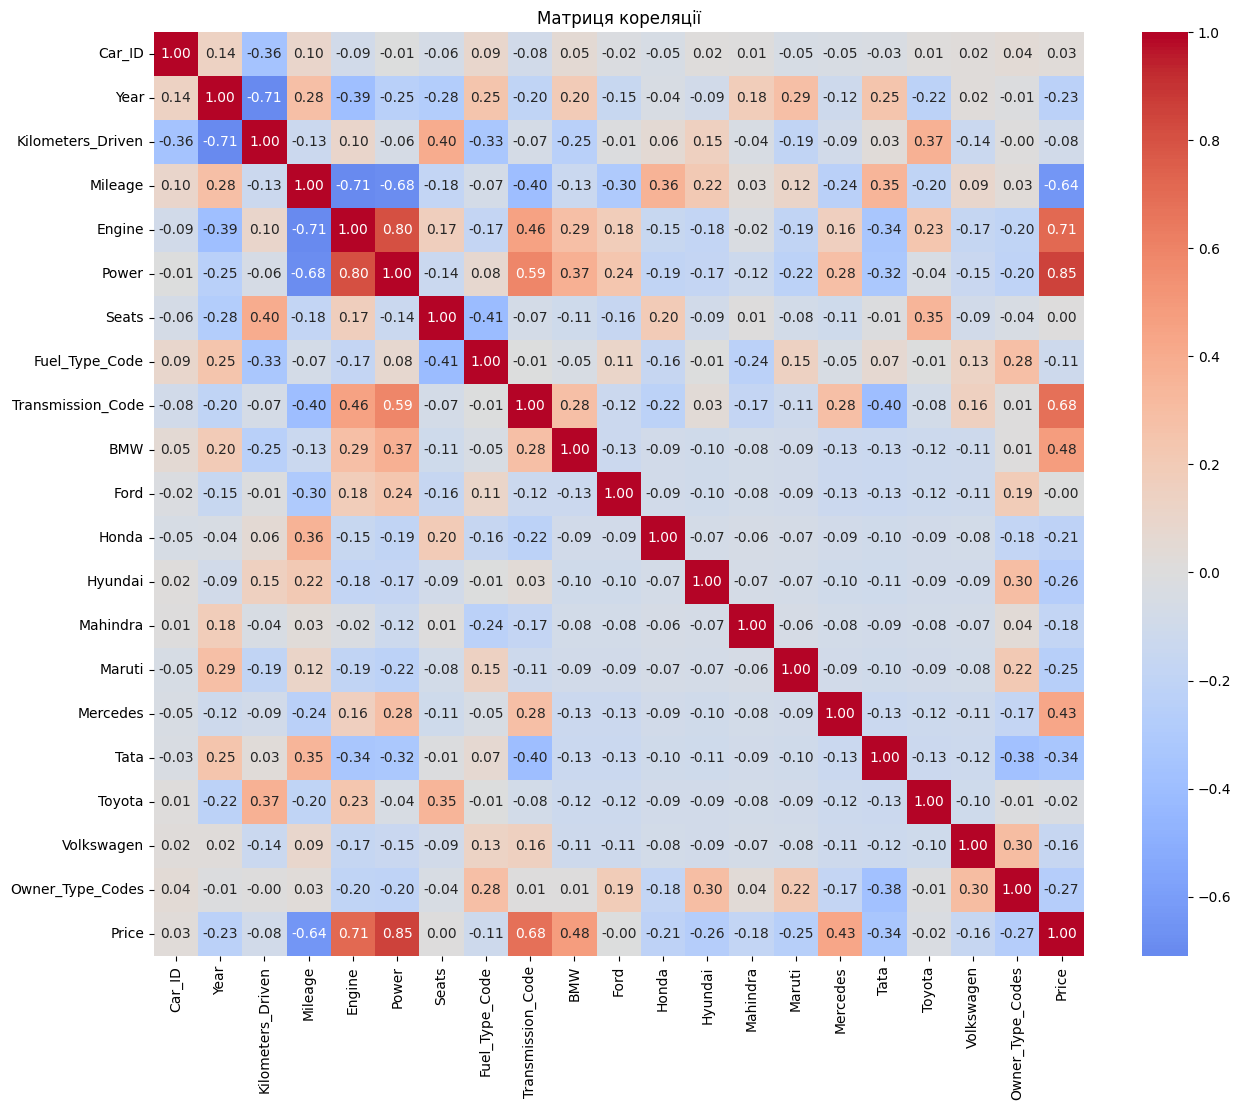

Кореляції з Price понад 0.5 за модулем:
Mileage             -0.638
Engine               0.711
Power                0.849
Transmission_Code    0.681
Name: Price, dtype: float64


In [21]:
X_train = X_train.select_dtypes('number')
X_test = X_test.select_dtypes('number')

train_data = pd.concat([X_train, y_train], axis=1)
corr = train_data.corr()

plt.figure(figsize=(15, 12))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Матриця кореляції')
plt.show()

price_corr = corr['Price'].drop('Price')
print('Кореляції з Price понад 0.5 за модулем:')
print(price_corr[price_corr.abs() > 0.5].round(3))

**Висновок**: Найсильніша позитивна кореляція з ціною спостерігається у Power (0,849), Engine (0,711) та Transmission_Code (0,681). Mileage має негативну кореляцію з ціною (-0,638). Інші ознаки мають кореляцію з ціною не більше 0,5 за модулем. Отже, потужність двигуна найбільше пов’язана з ціною серед розглянутих ознак.

**Завдання 6**. Тренуємо лінійну регресію.
0. Видаліть усі НЕчислові колонки з `X_train`, `X_test`, якщо ще цього не зробили.
1. Натренуйте лінійну регресую з `sklearn` на усіх числових даних тренувального набору `X_train`.
2. Зробіть передбачення на  `X_train`, `X_test`. Знайдіть і виведіть root mean squared error відхилення передбачення від справжніх значень цільової змінної.
3. Побудуйте графік розсіювання передбачень проти реальних даних цільової змінної для тренувального і тестувального наборів даних. Що можете сказати про якість моделі?

RMSE train: 210293.58
RMSE test: 258181.56


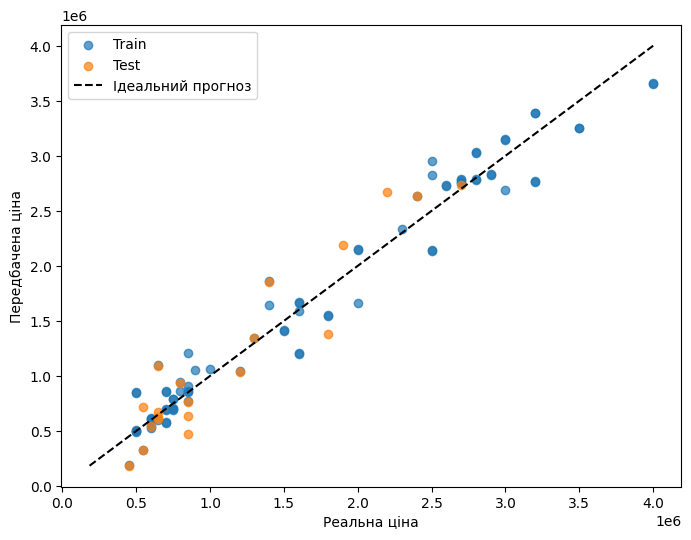

In [22]:
model = LinearRegression()
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))
print('RMSE train:', round(rmse_train, 2))
print('RMSE test:', round(rmse_test, 2))

plt.figure(figsize=(8, 6))
plt.scatter(y_train, pred_train, label='Train', alpha=0.7)
plt.scatter(y_test, pred_test, label='Test', alpha=0.7)
low = min(y.min(), pred_train.min(), pred_test.min())
high = max(y.max(), pred_train.max(), pred_test.max())
plt.plot([low, high], [low, high], '--', color='black', label='Ідеальний прогноз')
plt.xlabel('Реальна ціна')
plt.ylabel('Передбачена ціна')
plt.legend()
plt.show()

**Висновок*: RMSE на тренувальних даних становить 210 293,58 рупії, а на тестових — 258 181,56 рупії. На графіку більшість точок розташована близько до діагональної лінії, хоча є помітні відхилення. Помилка на тестових даних більша. Модель загалом передає залежність між характеристиками автомобіля та його ціною, але не завжди точно прогнозує окремі ціни.

**Завдання 7**. Ми хочемо проаналізувати як впливає кожен чинник на цілову змінну. Для цього давайте промасштабуємо наші дані.
1. Зробіть масштабування незалежних змінних використовуючи `StandardScaler`. Тренуємо на тренувальних даних, а на тестувальних лише викликаємо `transform`.

2. Натренуйте модель на відмасштабованих даних і перегляньте коефіцієнти моделі. Які колонки є найвпливовішими на формування передбачення з точки зору коефіцієнтів? Проаналізуйте напрям дії найважливіших коефіцієнтів. Чи це логічно з точки зору значення відповідних змінних, що вони впливають на цільову змінну саме в напрямі збільшення / зменшення?

In [25]:
scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled,
                              columns=X_train.columns,
                              index=X_train.index)

X_test_scaled = pd.DataFrame(X_test_scaled,
                             columns=X_test.columns,
                             index=X_test.index)

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

coef = pd.Series(model_scaled.coef_, index=X_train.columns)

coef = coef.reindex(coef.abs().sort_values(ascending=False).index)

print(coef.round(2))

Power                496769.21
Ford                -334761.66
Hyundai             -332815.86
Tata                -292649.11
Mahindra            -290310.21
Volkswagen          -286620.55
Maruti              -278152.87
Honda               -228645.91
Toyota              -189794.45
Fuel_Type_Code      -183848.02
Mileage             -131715.51
Transmission_Code    116693.77
Kilometers_Driven    -94398.72
Owner_Type_Codes      42344.95
Engine               -21377.45
Year                  -8765.65
BMW                   -8144.89
Mercedes              -6503.42
Car_ID                 5608.69
Seats                 -2148.92
dtype: float64


**Висновок**: Найбільший за модулем коефіцієнт має Power (496 769,21), тобто більша потужність пов’язана з вищою ціною за інших незмінних ознак. Також великі від’ємні коефіцієнти мають Ford (-334 761,66) та Hyundai (-332 815,86) порівняно з базовим брендом Audi. Mileage має від’ємний коефіцієнт, а автоматична коробка передач — додатний. Від’ємний коефіцієнт Engine не збігається з його позитивною кореляцією з ціною, що може бути пов’язано із сильною кореляцією Engine та Power. Car_ID залишено за умовою використання всіх числових колонок, але для реальної моделі ідентифікатор краще не використовувати.

**Завдання 8.** На тих самих відмасштабованих даних натренуйте модель з `statsmodels`. Виведіть звіт і проаналізуйте p-value коефіцієнтів. Які ознаки є стат значущими на рівні значущості 0.05? Напишіть їх список.

In [26]:
X_train_sm = sm.add_constant(X_train_scaled, has_constant='add')
X_test_sm = sm.add_constant(X_test_scaled, has_constant='add')
model_full = sm.OLS(y_train, X_train_sm).fit()
print(model_full.summary())

p_values = model_full.pvalues.drop('const')
significant = p_values[p_values < 0.05].index.tolist()
print('\nСтатистично значущі ознаки:', significant)

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.959
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     68.35
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           2.01e-33
Time:                        12:19:32   Log-Likelihood:                -1094.0
No. Observations:                  80   AIC:                             2230.
Df Residuals:                      59   BIC:                             2280.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               1.68e+06   2.74e+0

**Висновок по статистично значущим ознакам (p-value < 0,05)**: Mileage, Power, Fuel_Type_Code, Transmission_Code, Ford, Honda, Hyundai, Mahindra, Maruti, Tata, Toyota та Volkswagen. Для інших ознак p-value не менше 0,05.

**Завдання 9**. Натренуйте лінійну регресію з `statsmodels` тільки на ознаках, які виявлись стат. значущими в попередньому завданні. Проаналізуйте показники моделі. Чи значно змінились R2 і Adj. R-squared?

In [27]:
model_005 = sm.OLS(y_train, sm.add_constant(X_train_scaled[significant], has_constant='add')).fit()
print(model_005.summary())
print('\nR2 повної моделі:', round(model_full.rsquared, 4))
print('R2 скороченої моделі:', round(model_005.rsquared, 4))
print('Adj. R2 повної моделі:', round(model_full.rsquared_adj, 4))
print('Adj. R2 скороченої моделі:', round(model_005.rsquared_adj, 4))

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     116.1
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           6.31e-40
Time:                        12:23:36   Log-Likelihood:                -1098.2
No. Observations:                  80   AIC:                             2222.
Df Residuals:                      67   BIC:                             2253.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               1.68e+06   2.71e+0

**Висновок**: Після відбору залишилось 12 ознак замість 20. R² зменшився з 0,9586 до 0,9541, а скоригований R² зріс з 0,9446 до 0,9459. Зміни невеликі, тому модель із меншою кількістю ознак майже не втратила якість на тренувальних даних. Вона є простішою для пояснення.

**Завдання 10**. Натренуйте лінійну регресію з `statsmodels` на усіх ознаках з масштабованого `X_train`, у яких p_value в завданні 8 менше за `0.25`. Ми таким чином помʼякшили критерій відбору ознак. Проаналізуйте показники моделі. Чи значно змінились R2 і Adj. R-squared порівняно з завданням 8? Яку модель з останніх 3х завдань ви б лишили для використання?

In [28]:
selected = p_values[p_values < 0.25].index.tolist()
print('Відібрані ознаки:', selected)
model_025 = sm.OLS(y_train, sm.add_constant(X_train_scaled[selected], has_constant='add')).fit()
print(model_025.summary())

pred_full = model_full.predict(X_test_sm)
pred_005 = model_005.predict(sm.add_constant(X_test_scaled[significant], has_constant='add'))
pred_025 = model_025.predict(sm.add_constant(X_test_scaled[selected], has_constant='add'))

results = pd.DataFrame({
    'R2': [model_full.rsquared, model_005.rsquared, model_025.rsquared],
    'Adj. R2': [model_full.rsquared_adj, model_005.rsquared_adj, model_025.rsquared_adj],
    'RMSE test': [np.sqrt(mean_squared_error(y_test, pred_full)), np.sqrt(mean_squared_error(y_test, pred_005)), np.sqrt(mean_squared_error(y_test, pred_025))]
}, index=['Усі ознаки', 'p < 0.05', 'p < 0.25'])
results.round(4)

Відібрані ознаки: ['Kilometers_Driven', 'Mileage', 'Power', 'Fuel_Type_Code', 'Transmission_Code', 'Ford', 'Honda', 'Hyundai', 'Mahindra', 'Maruti', 'Tata', 'Toyota', 'Volkswagen']
                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.950
Method:                 Least Squares   F-statistic:                     115.4
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           4.23e-40
Time:                        12:24:32   Log-Likelihood:                -1094.7
No. Observations:                  80   AIC:                             2217.
Df Residuals:                      66   BIC:                             2251.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                        coef 

,R2,Adj. R2,RMSE test
Усі ознаки,0.9586,0.9446,258181.5611
p < 0.05,0.9541,0.9459,259740.1628
p < 0.25,0.9579,0.9496,251802.6288


**Висновок**: За умовою p-value < 0,25 відібрали 13 ознак, додавши Kilometers_Driven до ознак попередньої моделі. R² становить 0,9579 проти 0,9586 у повної моделі, а скоригований R² зріс до 0,9496. RMSE на тестових даних становить 251 802,63 рупії, що менше, ніж у двох інших моделей. Я б обрав модель із завдання 10, оскільки вона має менше ознак, найвищий скоригований R² і найменшу помилку на цьому тестовому наборі. Для остаточної оцінки якості моделі бажано мати більше даних.